Question 13: Deploying a Vision Model on Edge (Jetson Nano or ONNX): Convert a trained model (YOLO or MobileNet) to ONNX or TensorRT and deploy it on an edge device. Measure FPS and inference time. 

In [ ]:
!pip install onnx onnxruntime onnxscript

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/cse2k26/cse2k2652/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 13.6M/13.6M [00:00<00:00, 35.7MB/s]
[W1107 16:27:33.708658159 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.730352608 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.749143956 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.767831231 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.787103490 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.807761153 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.827012229 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:33.845574612 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupporte

Exported Model Size: 13.34 MB
PyTorch Predicted Class ID on Real Image: 258
ONNX Predicted Class ID on Real Image:    258
Prediction Match: True


[W1107 16:27:35.076144791 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.078560995 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.080608566 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.082661050 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.085087190 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.087669449 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.090198079 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.092366620 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.094643631 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:27:35.096868363 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.


Platform             | Latency (ms)   | Throughput (FPS)
-------------------------------------------------------
PyTorch Native (CPU) |      34.99 ms |       28.6 FPS
ONNX Runtime (Edge)  |       5.35 ms |      186.9 FPS
Inference Acceleration: 6.54x Speedup via ONNX


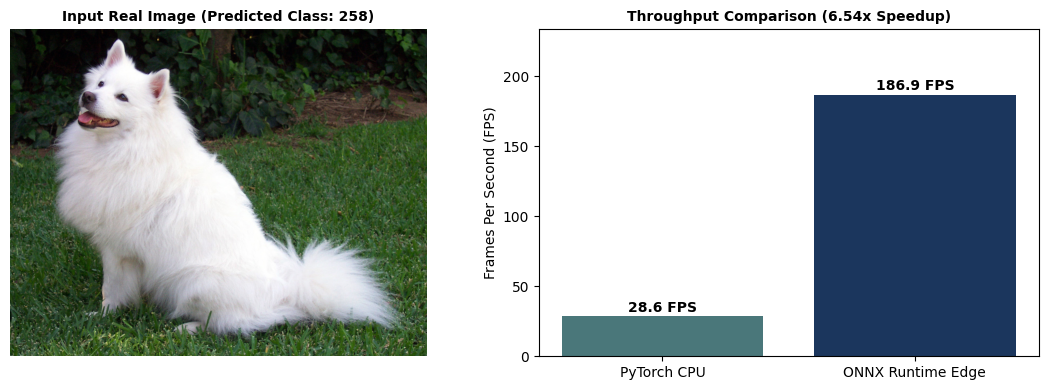

In [1]:
import time
import os
import urllib.request
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt
img_url = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
img_file = "real_dog_edge.jpg"
if not os.path.exists(img_file):
    urllib.request.urlretrieve(img_url, img_file)
pil_img = Image.open(img_file).convert("RGB")
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
real_input = preprocess(pil_img).unsqueeze(0)
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.eval()
onnx_filename = "mobilenet_v2_real_edge.onnx"
torch.onnx.export(
    model,
    real_input,
    onnx_filename,
    export_params=True,
    opset_version=12,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output']
)
onnx_model = onnx.load(onnx_filename)
onnx.checker.check_model(onnx_model)
file_size_mb = os.path.getsize(onnx_filename) / (1024 * 1024)
print(f"Exported Model Size: {file_size_mb:.2f} MB")
ort_session = ort.InferenceSession(onnx_filename, providers=['CPUExecutionProvider'])
ort_input = {ort_session.get_inputs()[0].name: real_input.numpy()}
with torch.no_grad():
    pt_out = model(real_input)
    pt_top1 = torch.argmax(pt_out, dim=1).item()
ort_out = ort_session.run(None, ort_input)[0]
ort_top1 = np.argmax(ort_out, axis=1)[0]
print(f"PyTorch Predicted Class ID on Real Image: {pt_top1}")
print(f"ONNX Predicted Class ID on Real Image:    {ort_top1}")
print(f"Prediction Match: {pt_top1 == ort_top1}")
ITERATIONS = 50
with torch.no_grad():
    for _ in range(5): _ = model(real_input)
    start_pt = time.time()
    for _ in range(ITERATIONS):
        _ = model(real_input)
    pt_time = (time.time() - start_pt) / ITERATIONS
for _ in range(5): _ = ort_session.run(None, ort_input)
start_ort = time.time()
for _ in range(ITERATIONS):
    _ = ort_session.run(None, ort_input)
ort_time = (time.time() - start_ort) / ITERATIONS
pt_fps = 1.0 / pt_time
ort_fps = 1.0 / ort_time
speedup = pt_time / ort_time
print("" + "="*55)
print(f"{'Platform':<20} | {'Latency (ms)':<14} | {'Throughput (FPS)':<12}")
print("-" * 55)
print(f"{'PyTorch Native (CPU)':<20} | {pt_time*1000:>10.2f} ms | {pt_fps:>10.1f} FPS")
print(f"{'ONNX Runtime (Edge)':<20} | {ort_time*1000:>10.2f} ms | {ort_fps:>10.1f} FPS")
print(f"Inference Acceleration: {speedup:.2f}x Speedup via ONNX")
print("="*55)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(pil_img)
axes[0].set_title(f"Input Real Image (Predicted Class: {ort_top1})", fontsize=10, fontweight='bold')
axes[0].axis('off')
bars = axes[1].bar(['PyTorch CPU', 'ONNX Runtime Edge'], [pt_fps, ort_fps], color=['#4A777A', '#1B365D'])
axes[1].set_title(f"Throughput Comparison ({speedup:.2f}x Speedup)", fontsize=10, fontweight='bold')
axes[1].set_ylabel("Frames Per Second (FPS)")
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f} FPS", ha='center', va='bottom', fontweight='bold')
axes[1].set_ylim(0, max(pt_fps, ort_fps) * 1.25)
plt.tight_layout()
plt.show()
